<a href="https://colab.research.google.com/github/Iucasoa/Sistemas-Inteligentes/blob/main/problema3-knn/notebook.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Classificando a Qualidade de Vinhos Tintos com k-NN

Neste projeto, vamos construir e testar um modelo usando o algoritmo **k-Nearest Neighbors (k-NN)** para classificar vinhos tintos em três categorias: "ruim", "médio" ou "bom". Passaremos por todas as etapas clássicas de um projeto de Machine Learning: desde a análise inicial dos dados, passando pelo pré-processamento e escolha do melhor valor de $k$, até a avaliação detalhada dos resultados reais.

## 1. Importação de Bibliotecas

Primeiro, vamos carregar as bibliotecas básicas do ecossistema Python. Usaremos `pandas` e `numpy` para organizar e manipular os dados, `matplotlib` e `seaborn` para criar os gráficos, e o `scikit-learn` para toda a parte de modelagem, validação e cálculo das métricas de desempenho.

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import make_pipeline
from sklearn.metrics import confusion_matrix, classification_report, accuracy_score

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 6)

## 2. Carregamento do Dataset

Vamos importar a base de dados de vinhos tintos (*Wine Quality*) diretamente do repositório da UCI. Esse arquivo traz 11 medições físico-químicas de diferentes vinhos e uma nota de qualidade de 3 a 8 que foi dada por especialistas.

In [ ]:
url = "https://archive.ics.uci.edu/ml/machine-learning-databases/wine-quality/winequality-red.csv"
df = pd.read_csv(url, sep=";")

# Alternativa, se a URL não abrir (baixe o winequality-red.csv da UCI e descomente):
# from google.colab import files
# files.upload()
# df = pd.read_csv("winequality-red.csv", sep=";")

## 3. Inspeção Inicial e Análise Exploratória

Hora de dar uma primeira olhada nos dados. Vamos verificar o tamanho da nossa tabela, checar se existem valores em branco (nulos) que precisam ser tratados, e ver como as notas de qualidade estão distribuídas na base original.

In [ ]:
print("Dimensão:", df.shape)   # esperado: (1599, 12)
display(df.head())
display(df.describe().T)

print("\nValores ausentes por coluna:")
print(df.isnull().sum())

print("\nNotas originais de qualidade:")
print(df["quality"].value_counts().sort_index())

Dimensão: (1599, 12)


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5


,count,mean,std,min,25%,50%,75%,max
fixed acidity,1599.0,8.319637,1.741096,4.60000,7.1000,7.90000,9.200000,15.90000
volatile acidity,1599.0,0.527821,0.179060,0.12000,0.3900,0.52000,0.640000,1.58000
citric acid,1599.0,0.270976,0.194801,0.00000,0.0900,0.26000,0.420000,1.00000
residual sugar,1599.0,2.538806,1.409928,0.90000,1.9000,2.20000,2.600000,15.50000
chlorides,1599.0,0.087467,0.047065,0.01200,0.0700,0.07900,0.090000,0.61100
free sulfur dioxide,1599.0,15.874922,10.460157,1.00000,7.0000,14.00000,21.000000,72.00000
total sulfur dioxide,1599.0,46.467792,32.895324,6.00000,22.0000,38.00000,62.000000,289.00000
density,1599.0,0.996747,0.001887,0.99007,0.9956,0.99675,0.997835,1.00369
pH,1599.0,3.311113,0.154386,2.74000,3.2100,3.31000,3.400000,4.01000
sulphates,1599.0,0.658149,0.169507,0.33000,0.5500,0.62000,0.730000,2.00000



Valores ausentes por coluna:
fixed acidity           0
volatile acidity        0
citric acid             0
residual sugar          0
chlorides               0
free sulfur dioxide     0
total sulfur dioxide    0
density                 0
pH                      0
sulphates               0
alcohol                 0
quality                 0
dtype: int64

Notas originais de qualidade:
quality
3     10
4     53
5    681
6    638
7    199
8     18
Name: count, dtype: int64


### O que os dados mostram?

Temos $1599$ vinhos e nenhuma informação em falta. A imensa maioria se concentra nas notas intermediárias como 5 ($681$ amostras) e 6 ($638$ amostras). Já os vinhos excelentes (nota 8, apenas $18$ vinhos) ou ruins (nota 3, apenas $10$ vinhos) são bem raros. Esse desbalanceamento forte vai exigir atenção na separação dos conjuntos.

## 4. Agrupando as Notas de Qualidade em Classes

Como as notas estão muito espalhadas e algumas têm pouquíssimas amostras, vamos simplificar o problema. Vamos agrupar as notas de qualidade em três categorias fáceis de entender:
* **Ruim**: notas de 3 a 5.
* **Médio**: notas 6 e 7.
* **Bom**: nota 8.

Em seguida, veremos como ficou a distribuição física dos vinhos nestas novas classes.

In [ ]:
def classificar(nota):
    if nota <= 5:
        return "ruim"
    elif nota <= 7:
        return "médio"
    else:
        return "bom"

ordem = ["ruim", "médio", "bom"]
df["classe"] = df["quality"].apply(classificar)

print(df["classe"].value_counts().reindex(ordem))
print((df["classe"].value_counts(normalize=True).reindex(ordem) * 100).round(2))

classe
ruim     744
médio    837
bom       18
Name: count, dtype: int64
classe
ruim     46.53
médio    52.35
bom       1.13
Name: proportion, dtype: float64


### Como ficou nossa divisão por classes?

A classe "médio" responde por $52.35\%$ ($837$ amostras) e a "ruim" por $46.53\%$ ($744$ amostras). O nosso gargalo será a classe "bom", com apenas $1.13\%$ ($18$ amostras). Com tão pouca representação, o modelo provavelmente terá bastante dificuldade para classificar os vinhos excelentes.

## 5. Separando os Dados em Treino e Teste (com Estratificação)

Para validar nosso modelo de forma justa, separamos $80\%$ dos dados para treino ($1279$ amostras) e guardamos $20\%$ para teste ($320$ amostras). Usamos a estratificação para garantir que a proporção de vinhos ruins, médios e bons seja idêntica nas duas partes. Também calculamos nossa taxa de acerto inicial (baseline), que seria a acurácia de um modelo simples que apenas chuta a classe mais comum para todos os vinhos.

In [ ]:
X = df.drop(columns=["quality", "classe"])
y = df["classe"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)
print("Treino:", len(X_train), "| Teste:", len(X_test))
print("\nClasses no teste:")
print(y_test.value_counts().reindex(ordem))

print("\nBaseline (sempre prever a classe majoritária):",
      round(y_train.value_counts(normalize=True).max(), 4))

Treino: 1279 | Teste: 320

Classes no teste:
classe
ruim     149
médio    167
bom        4
Name: count, dtype: int64

Baseline (sempre prever a classe majoritária): 0.5238


### Proporções e nosso ponto de partida

A divisão preservou as proporções: nosso teste de 320 vinhos ficou com $149$ ruins, $167$ médios e $4$ bons. O nosso ponto de partida (baseline) é de $0.5238$ ($52.38\%$) de acurácia, que seria a taxa de acerto caso apenas chutássemos "médio" para todas as previsões.

## 6. Por que Precisamos Ajustar as Escalas dos Dados?

O k-NN funciona medindo distâncias geométricas entre os pontos. Se uma variável tem valores muito altos (como o dióxido de enxofre) e outra tem valores muito pequenos (como a acidez volátil), os valores maiores vão dominar o cálculo de distância, e o modelo vai ignorar os atributos menores. Para provar isso, vamos testar o desempenho do modelo usando validação cruzada em 5 dobras com e sem o uso do `StandardScaler`.

In [ ]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

sem = cross_val_score(KNeighborsClassifier(n_neighbors=11), X_train, y_train, cv=cv).mean()
com = cross_val_score(make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=11)),
                      X_train, y_train, cv=cv).mean()
print(f"Acurácia CV sem normalização: {sem:.4f}")
print(f"Acurácia CV com normalização: {com:.4f}")

Acurácia CV sem normalização: 0.6216
Acurácia CV com normalização: 0.7115


### Impacto do ajuste de escalas

Os testes mostram que padronizar os dados é indispensável para o k-NN:
- **Sem padronizar:** Acurácia média de $0.6216$.
- **Com padronizar (StandardScaler):** Acurácia média sobe para $0.7115$.

São quase 9 pontos percentuais de diferença, provando que sem escalas uniformes as variáveis com valores altos distorcem completamente a análise geométrica do modelo.

## 7. Escolhendo o Melhor Valor de $k$ com Validação Cruzada

Agora vamos descobrir quantos "vizinhos" ($k$) nosso modelo deve consultar para tomar a melhor decisão. Vamos testar vários valores de $k$ de 1 a 51. Para evitar que os dados de validação influenciem o treinamento (o que chamamos de vazamento de dados), usamos um Pipeline que aplica a padronização de escalas estritamente dentro de cada uma das 5 dobras da validação cruzada.

In [ ]:
valores_k = [1, 3, 5, 7, 9, 11, 15, 21, 31, 51]
linhas = []

for k in valores_k:
    pipe = make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=k))
    r = cross_validate(pipe, X_train, y_train, cv=cv,
                       scoring="accuracy", return_train_score=True)
    linhas.append((k, r["train_score"].mean(), r["test_score"].mean(), r["test_score"].std()))

tabela = pd.DataFrame(linhas, columns=["k", "acc_treino", "acc_validacao", "desvio"])
display(tabela.round(4))

k_otimo = int(tabela.loc[tabela["acc_validacao"].idxmax(), "k"])
print("k escolhido:", k_otimo)

,k,acc_treino,acc_validacao,desvio
0,1,1.0000,0.7248,0.0214
1,3,0.8362,0.6888,0.0175
2,5,0.7871,0.7013,0.0207
3,7,0.7766,0.7060,0.0332
4,9,0.7631,0.7170,0.0339
5,11,0.7617,0.7115,0.0361
6,15,0.7508,0.7193,0.0300
7,21,0.7441,0.7138,0.0332
8,31,0.7303,0.7146,0.0299
9,51,0.7275,0.7162,0.0188


k escolhido: 1


### Qual o melhor valor de k?

O teste de validação indicou $k = 1$ como ideal, obtendo acurácia média de $0.7248$ (desvio de $0.0214$). Contudo, teoricamente, $k=1$ costuma ser muito instável e suscetível a ruído. Uma hipótese provável (não testada diretamente) é que a presença de amostras duplicadas no dataset acabe beneficiando esse valor de $k$.

## 8. Visualizando o Desempenho do k-NN para Diferentes Valores de $k$

Para entender melhor como a complexidade do modelo afeta o aprendizado, vamos criar um gráfico de linhas mostrando as acurácias obtidas nos dados de treino e nos dados de validação para cada valor de $k$ avaliado.

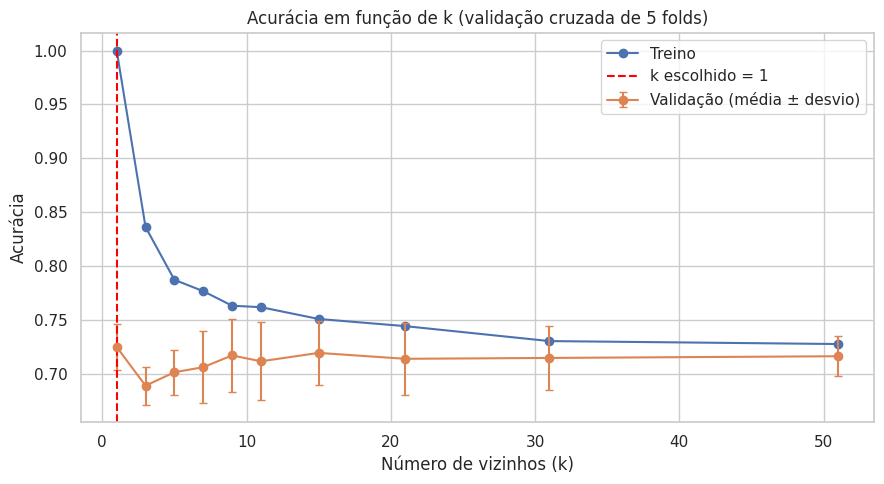

In [ ]:
plt.figure(figsize=(9, 5))
plt.plot(tabela["k"], tabela["acc_treino"], marker="o", label="Treino")
plt.errorbar(tabela["k"], tabela["acc_validacao"], yerr=tabela["desvio"],
             marker="o", capsize=3, label="Validação (média ± desvio)")
plt.axvline(k_otimo, color="red", linestyle="--", label=f"k escolhido = {k_otimo}")
plt.xlabel("Número de vizinhos (k)")
plt.ylabel("Acurácia")
plt.title("Acurácia em função de k (validação cruzada de 5 folds)")
plt.legend()
plt.tight_layout()
plt.savefig("curva_k.png", dpi=300)
plt.show()

### Análise visual do erro

O gráfico deixa claro o efeito de sobreajuste (*overfitting*) com vizinhos muito baixos. Para $k=1$, a taxa de acerto no treino é perfeita de $1.0000$ ($100\%$) contra $0.7248$ na validação. Conforme aumentamos $k$, as curvas se aproximam, sinalizando um modelo com comportamento de decisão mais suave e geral.

## 9. Treinamento Final e Avaliação no Conjunto de Teste

Com os parâmetros definidos ($k=1$ e uso de padronização de escalas), vamos treinar o modelo utilizando todo o nosso conjunto de treino. Em seguida, faremos as previsões nas 320 amostras do conjunto de teste (dados inéditos) para ver como o classificador se sai na vida real.

In [ ]:
scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)
X_test_s = scaler.transform(X_test)

modelo = KNeighborsClassifier(n_neighbors=k_otimo)
modelo.fit(X_train_s, y_train)
y_pred = modelo.predict(X_test_s)

print(f"Acurácia no teste: {accuracy_score(y_test, y_pred):.4f}\n")
print(classification_report(y_test, y_pred, labels=ordem, zero_division=0))

Acurácia no teste: 0.7656

              precision    recall  f1-score   support

        ruim       0.77      0.75      0.76       149
       médio       0.76      0.80      0.78       167
         bom       0.00      0.00      0.00         4

    accuracy                           0.77       320
   macro avg       0.51      0.52      0.51       320
weighted avg       0.76      0.77      0.76       320



### Desempenho real do classificador

Atingimos acurácia final de $0.7656$ ($76.56\%$) no teste, batendo com folga o baseline ingênuo ($52.38\%$). Apesar disso, o resultado esconde uma falha crítica na classe mais rara:
- **Ruim:** F1-score de $0.76$ (Precisão: $0.77$, Recall: $0.75$).
- **Médio:** F1-score de $0.78$ (Precisão: $0.76$, Recall: $0.80$).
- **Bom:** F1-score de $0.00$ (Precisão e Recall nulos).

Nenhuma das $4$ amostras ótimas foi detectada (recall zero). O F1-score macro médio de $0.51$ resume bem esse desequilíbrio.

## 10. Analisando Onde o Modelo Erra com a Matriz de Confusão

Para entender detalhadamente quais classes estão confundindo nosso modelo, vamos desenhar uma matriz de confusão. Ela mostra visualmente as decisões corretas e os cruzamentos onde ocorreram os erros de classificação.

            prev ruim  prev médio  prev bom
real ruim         112          37         0
real médio         33         133         1
real bom            0           4         0


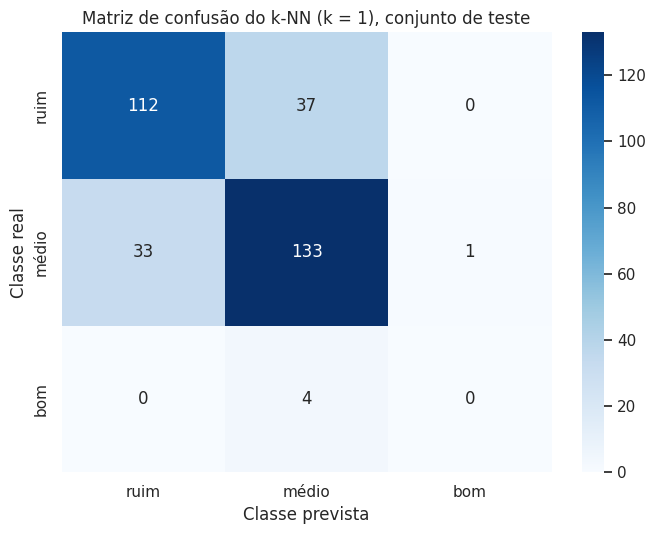

In [ ]:
cm = confusion_matrix(y_test, y_pred, labels=ordem)
print(pd.DataFrame(cm, index=[f"real {c}" for c in ordem],
                   columns=[f"prev {c}" for c in ordem]))

plt.figure(figsize=(7, 5.5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=ordem, yticklabels=ordem)
plt.xlabel("Classe prevista")
plt.ylabel("Classe real")
plt.title(f"Matriz de confusão do k-NN (k = {k_otimo}), conjunto de teste")
plt.tight_layout()
plt.savefig("matriz_confusao.png", dpi=300)
plt.show()

### Onde estão acontecendo os erros?

A matriz confirma que as falhas se concentram nas fronteiras vizinhas: $70$ dos $75$ erros totais foram confusões diretas entre "ruim" e "médio" ($37$ vinhos ruins rotulados como médios, e $33$ médios tidos como ruins). Além disso, todos os $4$ vinhos excelentes ("bom") acabaram sendo rotulados de forma errônea como "médio" devido à falta de densidade amostral para o algoritmo aprender essa diferenciação.

## 11. Exportando os Gráficos do Projeto

Para encerrar, salvamos e exportamos em alta resolução as duas figuras mais importantes deste relatório técnico: a curva de ajuste do hiperparâmetro $k$ e a matriz de confusão final. Esses arquivos podem ser baixados e facilmente anexados em apresentações acadêmicas ou relatórios de engenharia.

In [ ]:
from google.colab import files
files.download("curva_k.png")
files.download("matriz_confusao.png")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>